# Gut Microbiome in Colorectal Disease
Data files (metadata.csv, seqtab_nochim_export.xlsx, taxa_species_export.xlsx): https://drive.google.com/drive/folders/1mRmZJeUs6zHTePn31OJcnt7LbPsqytfi?usp=sharing

Datasets from Kaggle:

https://www.kaggle.com/datasets/aramelheni/crc-gut-microbiome-ml-data

## 1. Setup: libraries and helper functions


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from scipy import stats
from scipy.spatial.distance import pdist, squareform
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

sns.set_theme(style="whitegrid")
RNG = np.random.default_rng(42)          # fixed seed for reproducible results

ORDER = ["Healthy", "Adenomatous Polyps", "Colorectal cancer"]   # disease progression order
PALETTE = {"Healthy": "#2ca02c", "Adenomatous Polyps": "#1f77b4", "Colorectal cancer": "#ff7f0e"}


def bh_adjust(pvals):
    """Benjamini-Hochberg correction for multiple comparisons (FDR)."""
    p = np.asarray(pvals, dtype=float)
    n = len(p)
    order = np.argsort(p)
    ranked = p[order] * n / (np.arange(n) + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty(n)
    out[order] = np.minimum(ranked, 1.0)
    return out

## 2. Visual identity: chart theme.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define the Monochromatic Dark color palette (Hex Codes)
tech_blue_palette = [
    "#DBD8E3",  # Light grey-purple
    "#A3AEB8",  # Medium grey
    "#5F6B75",  # Dark slate blue
    "#6B6E77",  # Additional grey 1
    "#474A56",  # Additional grey 2
    "#383B44",  # Additional grey 3
    "#2A2C33"   # Additional dark grey
]

# 2. Set the clean dark-grid theme (ideal for dark reports, presentations, and dashboards)
sns.set_theme(style="darkgrid")
sns.set_palette(sns.color_palette(tech_blue_palette))

# 3. Configure global properties for professional report-ready charts
plt.rcParams.update({
    'figure.facecolor': '#1E1E1E',  # Outer figure dark background
    'axes.facecolor': '#1E1E1E',    # Dark background for the plot area
    'axes.edgecolor': '#474A56',    # Slate axes border
    'axes.labelcolor': '#DBD8E3',   # Light axes labels for clarity
    'text.color': '#DBD8E3',        # Light text color
    'xtick.color': '#A3AEB8',       # X-axis ticks color
    'ytick.color': '#A3AEB8',       # Y-axis ticks color
    'grid.color': '#383B44',        # Soft dark gridlines color
    'grid.alpha': 0.5               # Gridline transparency
})

# 4. Group colors used by every chart (light to dark follows the disease progression)
PALETTE = {
    "Healthy": "#DBD8E3",             # Light grey-purple
    "Adenomatous Polyps": "#A3AEB8",  # Medium grey
    "Colorectal cancer": "#5F6B75"    # Dark slate blue
}

print("Monochromatic Dark visual identity applied successfully!")

Monochromatic Dark visual identity applied successfully!


## 3. Upload the data files

In [ ]:
from google.colab import files
File = files.upload()

Saving metadata.csv to metadata.csv
Saving seqtab_nochim_export.xlsx to seqtab_nochim_export.xlsx
Saving taxa_species_export.xlsx to taxa_species_export.xlsx


## 4. Load, clean, and match the data

In [ ]:
# Metadata is semicolon-separated
metadata_df = pd.read_csv("metadata.csv", sep=";")
metadata_df.columns = metadata_df.columns.str.strip()
for col in ["SampleID", "host_disease", "SampleName", "DiseaseStatus", "Sex"]:
    metadata_df[col] = metadata_df[col].astype(str).str.strip()

# Rows = samples, columns = ASVs
seqtab_df = pd.read_excel("seqtab_nochim_export.xlsx", index_col=0)
seqtab_df.index = seqtab_df.index.astype(str).str.strip()

# Rows = ASVs, columns = taxonomic ranks
taxa_df = pd.read_excel("taxa_species_export.xlsx", index_col=0)
taxa_df = (taxa_df.apply(lambda s: s.astype(str).str.strip())
                  .replace({"": np.nan, "nan": np.nan, "None": np.nan}))   # blanks become real NaN

# Sanity checks (fail immediately instead of printing a false success message)
assert metadata_df["host_disease"].is_unique, "host_disease contains duplicate values"
missing = set(metadata_df["host_disease"]) - set(seqtab_df.index)
assert not missing, f"Samples missing from seqtab: {sorted(missing)[:5]}"
assert set(seqtab_df.columns) <= set(taxa_df.index), "Some ASVs have no taxonomy in taxa_df"

# Match samples via host_disease (SampleID in metadata is the SRR accession, not the seqtab index)
meta = metadata_df.set_index("host_disease")
seqtab_df = seqtab_df.loc[meta.index]                  # same sample order in both tables
taxa_df = taxa_df.loc[seqtab_df.columns]               # same ASV order in both tables

print(f"Samples: {seqtab_df.shape[0]} | ASVs: {seqtab_df.shape[1]}")
print(meta["DiseaseStatus"].value_counts())
display(meta.head(3))

Samples: 59 | ASVs: 6693
DiseaseStatus
Colorectal cancer     21
Healthy               19
Adenomatous Polyps    19
Name: count, dtype: int64


,SampleID,SampleName,DiseaseStatus,Sex,Age
host_disease,,,,,
CRC1,SRR29923448,CT8,Colorectal cancer,male,76
CRC2,SRR29923449,CA1,Colorectal cancer,female,71
Healthy1,SRR29923450,H5,Healthy,male,58


## 5. Data quality: sequencing depth, age, and sex

In [ ]:
# Data quality: sequencing depth, age, and sex.
counts = seqtab_df.round().astype(np.int64)
depth = counts.sum(axis=1).rename("Total_Reads")

print("--- Sequencing depth (reads per sample) ---")
print(depth.describe().round(0))
if depth.min() < 1000:
    print("Warning: at least one sample has fewer than 1000 reads. Check its quality or exclude it.")

print("\n--- Age by group ---")
display(meta.groupby("DiseaseStatus")["Age"].agg(["count", "mean", "median", "std", "min", "max"]).loc[ORDER].round(2))

h_age, p_age = stats.kruskal(*[meta.loc[meta.DiseaseStatus == g, "Age"] for g in ORDER])
print(f"Kruskal-Wallis for age: H = {h_age:.3f} , p = {p_age:.4f}")

print("\n--- Sex by group ---")
sex_tab = pd.crosstab(meta["DiseaseStatus"], meta["Sex"]).loc[ORDER]
display(sex_tab)
chi2, p_sex, _, _ = stats.chi2_contingency(sex_tab)
print(f"Chi-square for sex: p = {p_sex:.4f}  (note: small counts reduce the reliability of this test)")

--- Sequencing depth (reads per sample) ---
count       59.0
mean      9914.0
std       2882.0
min       3844.0
25%       7591.0
50%       9746.0
75%      12018.0
max      16353.0
Name: Total_Reads, dtype: float64

--- Age by group ---


,count,mean,median,std,min,max
DiseaseStatus,,,,,,
Healthy,19,65.68,69.0,10.69,42,79
Adenomatous Polyps,19,64.53,65.0,10.27,42,79
Colorectal cancer,21,66.38,71.0,10.51,42,79


Kruskal-Wallis for age: H = 0.513 , p = 0.7739

--- Sex by group ---


Sex,female,male
DiseaseStatus,,
Healthy,10,9
Adenomatous Polyps,10,9
Colorectal cancer,10,11


Chi-square for sex: p = 0.9343  (note: small counts reduce the reliability of this test)


## 6. Equalizing depth (rarefaction) and alpha diversity

In [ ]:
# Rarefaction and Alpha Diversity calculations
def rarefy(table, target_depth, rng):
    """Randomly subsample (without replacement) the same number of reads from each sample."""
    out = np.zeros(table.shape, dtype=np.int64)
    for i, row in enumerate(table.values):
        out[i] = rng.multivariate_hypergeometric(row, target_depth)
    return pd.DataFrame(out, index=table.index, columns=table.columns)

def shannon(row):
    p = row[row > 0] / row.sum()
    return float(-(p * np.log(p)).sum())

def simpson(row):
    p = row / row.sum()
    return float(1 - (p ** 2).sum())

# Rarefy all samples to the depth of the smallest sample
rare_depth = int(depth.min())
rarefied = rarefy(counts, rare_depth, RNG)
print(f"All samples rarefied to {rare_depth:,} reads")

alpha = pd.DataFrame({
    "Shannon_Index": rarefied.apply(shannon, axis=1),
    "Simpson_Index": rarefied.apply(simpson, axis=1),
    "Observed_ASVs": (rarefied > 0).sum(axis=1),
})
analysis_df = meta.join(alpha).join(depth).reset_index()

# Does raw sequencing depth correlate with raw Shannon? (bias check)
raw_shannon = counts.apply(shannon, axis=1)
rho, p_rho = stats.spearmanr(depth, raw_shannon)
print(f"Spearman correlation between depth and raw Shannon: rho = {rho:.3f} , p = {p_rho:.4f}")

display(analysis_df[["host_disease", "DiseaseStatus", "Age", "Shannon_Index", "Simpson_Index", "Observed_ASVs", "Total_Reads"]].head())
display(analysis_df.groupby("DiseaseStatus")[["Shannon_Index", "Simpson_Index", "Observed_ASVs"]]
        .agg(["mean", "median", "std"]).loc[ORDER].round(3))

All samples rarefied to 3,844 reads
Spearman correlation between depth and raw Shannon: rho = 0.413 , p = 0.0012


,host_disease,DiseaseStatus,Age,Shannon_Index,Simpson_Index,Observed_ASVs,Total_Reads
0,CRC1,Colorectal cancer,76,6.027050,0.996950,568,12683
1,CRC2,Colorectal cancer,71,5.094059,0.992044,228,8689
2,Healthy1,Healthy,58,5.907246,0.996583,485,11817
3,Polype1,Adenomatous Polyps,69,5.120665,0.991835,299,16353
4,Healthy2,Healthy,63,5.591178,0.995374,363,8287


Shannon_Index               Simpson_Index                \
                            mean median    std          mean median    std   
DiseaseStatus                                                                
Healthy                    5.472  5.509  0.294         0.994  0.995  0.002   
Adenomatous Polyps         5.294  5.317  0.477         0.992  0.994  0.005   
Colorectal cancer          5.606  5.752  0.314         0.995  0.996  0.002   

                   Observed_ASVs                  
                            mean median      std  
DiseaseStatus                                     
Healthy                  356.632  364.0   85.928  
Adenomatous Polyps       318.211  299.0  106.016  
Colorectal cancer        395.048  439.0   95.718

## 7. Descriptive statistics and correlations

In [ ]:
# Descriptive statistics and correlation matrix
print("--- Structure of the sample-level table ---")
analysis_df.info()

print("\n--- Descriptive statistics of the Shannon index ---")
print("Mean    :", round(analysis_df["Shannon_Index"].mean(), 3))
print("Median  :", round(analysis_df["Shannon_Index"].median(), 3))
print("Std dev :", round(analysis_df["Shannon_Index"].std(), 3))

print("\n--- Descriptive statistics of age ---")
print("Age mean   :", round(analysis_df["Age"].mean(), 2))
print("Age median :", round(analysis_df["Age"].median(), 2))
print("Age std    :", round(analysis_df["Age"].std(), 2))

print("\n--- Summary of numeric variables ---")
num_cols = ["Age", "Shannon_Index", "Simpson_Index", "Observed_ASVs", "Total_Reads"]
display(analysis_df[num_cols].describe().round(2))

print("\n--- Correlation matrix ---")
display(analysis_df[num_cols].corr(numeric_only=True).round(2))

print("\n--- Group sizes ---")
display(analysis_df["DiseaseStatus"].value_counts())

--- Structure of the sample-level table ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59 entries, 0 to 58
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   host_disease   59 non-null     object 
 1   SampleID       59 non-null     object 
 2   SampleName     59 non-null     object 
 3   DiseaseStatus  59 non-null     object 
 4   Sex            59 non-null     object 
 5   Age            59 non-null     int64  
 6   Shannon_Index  59 non-null     float64
 7   Simpson_Index  59 non-null     float64
 8   Observed_ASVs  59 non-null     int64  
 9   Total_Reads    59 non-null     int64  
dtypes: float64(2), int64(3), object(5)
memory usage: 4.7+ KB

--- Descriptive statistics of the Shannon index ---
Mean    : 5.463
Median  : 5.574
Std dev : 0.385

--- Descriptive statistics of age ---
Age mean   : 65.56
Age median : 69.0
Age std    : 10.34

--- Summary of numeric variables ---


,Age,Shannon_Index,Simpson_Index,Observed_ASVs,Total_Reads
count,59.00,59.00,59.00,59.00,59.00
mean,65.56,5.46,0.99,357.93,9914.47
std,10.34,0.38,0.00,99.77,2882.47
min,42.00,4.26,0.98,145.00,3844.00
25%,58.00,5.20,0.99,282.50,7591.00
50%,69.00,5.57,0.99,364.00,9746.00
75%,75.00,5.76,1.00,449.00,12018.00
max,79.00,6.03,1.00,568.00,16353.00



--- Correlation matrix ---


,Age,Shannon_Index,Simpson_Index,Observed_ASVs,Total_Reads
Age,1.00,0.05,0.10,-0.01,-0.05
Shannon_Index,0.05,1.00,0.95,0.93,0.30
Simpson_Index,0.10,0.95,1.00,0.80,0.15
Observed_ASVs,-0.01,0.93,0.80,1.00,0.54
Total_Reads,-0.05,0.30,0.15,0.54,1.00



--- Group sizes ---


,count
DiseaseStatus,
Colorectal cancer,21
Healthy,19
Adenomatous Polyps,19


## 8. Statistical tests for alpha diversity

In [ ]:
# Statistical tests for alpha diversity
def kruskal_with_pairwise(df, value, group="DiseaseStatus", order=ORDER):
    """Kruskal-Wallis across all groups, then pairwise Mann-Whitney with BH correction."""
    samples = [df.loc[df[group] == g, value].dropna() for g in order]
    h, p = stats.kruskal(*samples)
    rows = []
    for a, b in combinations(order, 2):
        x = df.loc[df[group] == a, value].dropna()
        y = df.loc[df[group] == b, value].dropna()
        u, pw = stats.mannwhitneyu(x, y, alternative="two-sided")
        rows.append({"Group_A": a, "Group_B": b, "U": u, "p_value": pw})
    pairs = pd.DataFrame(rows)
    pairs["p_adj_BH"] = bh_adjust(pairs["p_value"])
    return h, p, pairs

kw_results = {}
for metric in ["Shannon_Index", "Simpson_Index", "Observed_ASVs"]:
    h, p, pairs = kruskal_with_pairwise(analysis_df, metric)
    kw_results[metric] = p
    print("=" * 60)
    print(f"{metric}:  Kruskal-Wallis H = {h:.3f} , p = {p:.4f}")
    display(pairs.round(4))
    if p < 0.05:
        verdict = "Statistically significant difference between groups"
    else:
        verdict = "No sufficient evidence of a difference (not proof of no difference: the sample size is small)"
    print("Conclusion:", verdict)

Shannon_Index:  Kruskal-Wallis H = 5.804 , p = 0.0549


,Group_A,Group_B,U,p_value,p_adj_BH
0,Healthy,Adenomatous Polyps,217.0,0.2933,0.2933
1,Healthy,Colorectal cancer,143.0,0.1293,0.1940
2,Adenomatous Polyps,Colorectal cancer,116.0,0.0246,0.0737


Conclusion: No sufficient evidence of a difference (not proof of no difference: the sample size is small)
Simpson_Index:  Kruskal-Wallis H = 5.633 , p = 0.0598


,Group_A,Group_B,U,p_value,p_adj_BH
0,Healthy,Adenomatous Polyps,203.0,0.5207,0.5207
1,Healthy,Colorectal cancer,134.5,0.0806,0.1210
2,Adenomatous Polyps,Colorectal cancer,119.0,0.0303,0.0908


Conclusion: No sufficient evidence of a difference (not proof of no difference: the sample size is small)
Observed_ASVs:  Kruskal-Wallis H = 5.125 , p = 0.0771


,Group_A,Group_B,U,p_value,p_adj_BH
0,Healthy,Adenomatous Polyps,225.0,0.1989,0.2497
1,Healthy,Colorectal cancer,156.5,0.2497,0.2497
2,Adenomatous Polyps,Colorectal cancer,120.5,0.0335,0.1005


Conclusion: No sufficient evidence of a difference (not proof of no difference: the sample size is small)


## 9. Chart 1: Shannon diversity

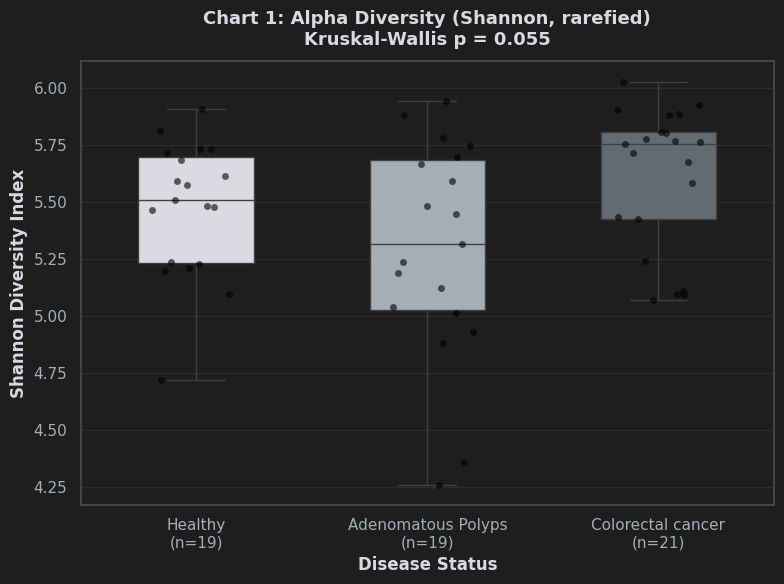

In [ ]:
#Chart 1: Alpha diversity
fig, ax = plt.subplots(figsize=(8, 6))
sns.boxplot(data=analysis_df, x="DiseaseStatus", y="Shannon_Index", order=ORDER, hue="DiseaseStatus",
            palette=PALETTE, width=0.5, showfliers=False, legend=False, ax=ax)   # no duplicate outlier points
sns.stripplot(data=analysis_df, x="DiseaseStatus", y="Shannon_Index", order=ORDER, color="black",
              alpha=0.6, jitter=0.2, size=5, ax=ax)

ns = analysis_df["DiseaseStatus"].value_counts()
ax.set_xticks(range(len(ORDER)))
ax.set_xticklabels([f"{g}\n(n={ns[g]})" for g in ORDER])
ax.set_title(f"Chart 1: Alpha Diversity (Shannon, rarefied)\nKruskal-Wallis p = {kw_results['Shannon_Index']:.3f}",
             fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Disease Status", fontsize=12, fontweight="bold")
ax.set_ylabel("Shannon Diversity Index", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

## 10. Beta diversity (PERMANOVA) and Chart 2: PCoA

PERMANOVA (3 groups): pseudo-F = 2.283 , p = 0.0010


,Group_A,Group_B,pseudo_F,p_value,p_adj_BH
0,Healthy,Adenomatous Polyps,2.6889,0.001,0.0015
1,Healthy,Colorectal cancer,2.4303,0.001,0.0015
2,Adenomatous Polyps,Colorectal cancer,1.7710,0.021,0.0210


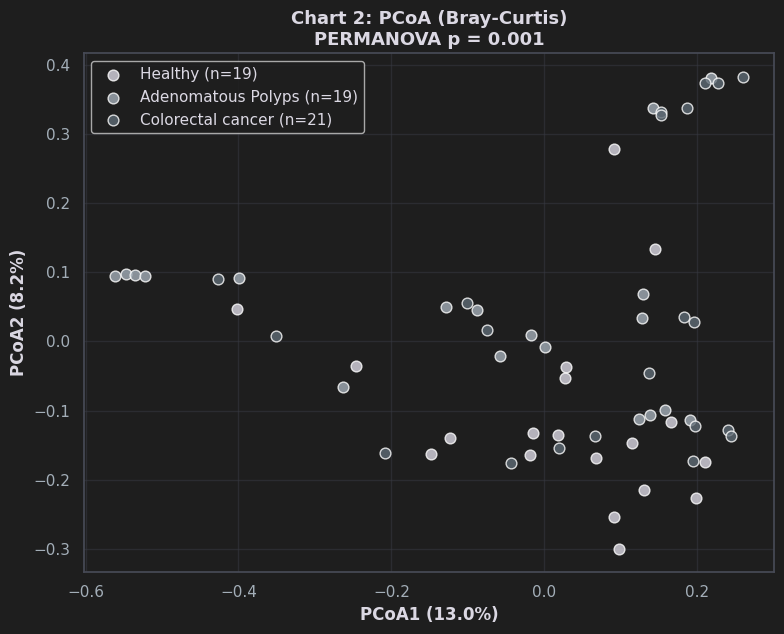

In [ ]:
# Chart 2: Beta diversity and PCoA
rel = counts.div(counts.sum(axis=1), axis=0)                    # relative abundance per sample (each row sums to 1)
D = squareform(pdist(rel.values, metric="braycurtis"))          # Bray-Curtis distance matrix

def pcoa(dist):
    """Principal Coordinates Analysis on a distance matrix."""
    n = dist.shape[0]
    J = np.eye(n) - np.ones((n, n)) / n
    B = J @ (-0.5 * dist ** 2) @ J                              # double-centered matrix
    vals, vecs = np.linalg.eigh(B)
    idx = np.argsort(vals)[::-1]
    vals, vecs = vals[idx], vecs[:, idx]
    pos = vals > 1e-10                                          # keep positive eigenvalues only
    return vecs[:, pos] * np.sqrt(vals[pos]), vals[pos] / vals[pos].sum()

def permanova(dist, labels, n_perm=999, rng=RNG):
    """PERMANOVA with a permutation p-value."""
    labels = np.asarray(labels)
    n, uniq = len(labels), np.unique(labels)
    a = len(uniq)
    sst = (dist ** 2)[np.triu_indices(n, 1)].sum() / n          # total sum of squares
    def pseudo_f(lab):
        ssw = 0.0                                               # within-group sum of squares
        for g in uniq:
            idx = np.where(lab == g)[0]
            sub = dist[np.ix_(idx, idx)]
            ssw += (sub ** 2)[np.triu_indices(len(idx), 1)].sum() / len(idx)
        return ((sst - ssw) / (a - 1)) / (ssw / (n - a))
    obs = pseudo_f(labels)
    perm = np.array([pseudo_f(rng.permutation(labels)) for _ in range(n_perm)])
    return obs, (1 + np.sum(perm >= obs)) / (n_perm + 1)

groups = meta["DiseaseStatus"].values
F, p_perm = permanova(D, groups)
print(f"PERMANOVA (3 groups): pseudo-F = {F:.3f} , p = {p_perm:.4f}")

# Pairwise PERMANOVA with BH correction
rows = []
for a, b in combinations(ORDER, 2):
    mask = np.isin(groups, [a, b])
    f, pp = permanova(D[np.ix_(mask, mask)], groups[mask])
    rows.append({"Group_A": a, "Group_B": b, "pseudo_F": f, "p_value": pp})
perm_pairs = pd.DataFrame(rows)
perm_pairs["p_adj_BH"] = bh_adjust(perm_pairs["p_value"])
display(perm_pairs.round(4))

# PCoA plot
coords, expl = pcoa(D)
fig, ax = plt.subplots(figsize=(8, 6.5))
for g in ORDER:
    m = groups == g
    ax.scatter(coords[m, 0], coords[m, 1], s=60, alpha=0.8, color=PALETTE[g],
               edgecolor="white", label=f"{g} (n={m.sum()})")
ax.set_xlabel(f"PCoA1 ({expl[0]*100:.1f}%)", fontsize=12, fontweight="bold")
ax.set_ylabel(f"PCoA2 ({expl[1]*100:.1f}%)", fontsize=12, fontweight="bold")
ax.set_title(f"Chart 2: PCoA (Bray-Curtis)\nPERMANOVA p = {p_perm:.3f}", fontsize=13, fontweight="bold")
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

## 11. Chart 3: Rarefaction curves

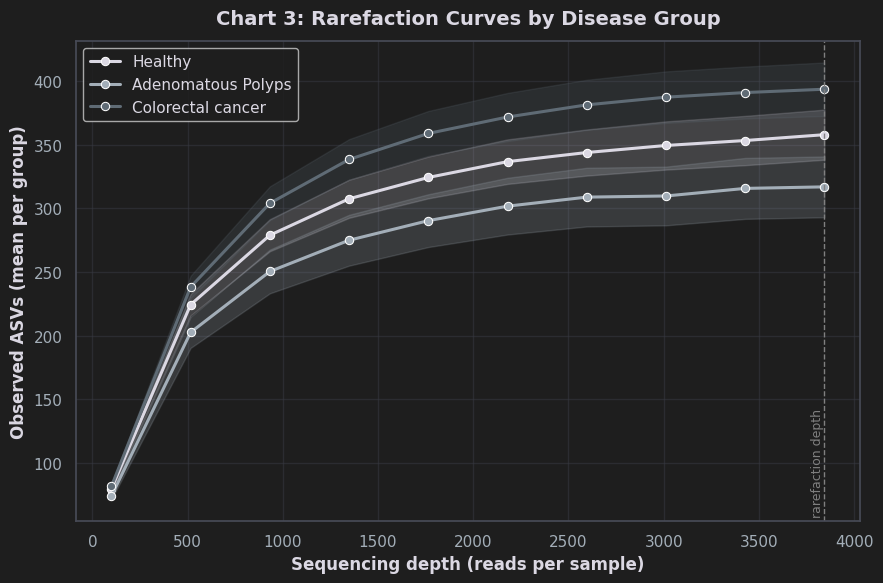

In [ ]:
#Chart 3: Rarefaction curves
# Observed ASVs at increasing sequencing depths, one line per disease group
depths = np.unique(np.linspace(100, rare_depth, 10).astype(int))
curve_rows = []
for d in depths:
    sub = rarefy(counts, int(d), RNG)                           # subsample every sample to depth d
    observed = (sub > 0).sum(axis=1)
    for sample, n_asv in observed.items():
        curve_rows.append({"Sample": sample, "Depth": int(d), "Observed_ASVs": int(n_asv),
                           "DiseaseStatus": meta.loc[sample, "DiseaseStatus"]})
curve_df = pd.DataFrame(curve_rows)

fig, ax = plt.subplots(figsize=(9, 6))
sns.lineplot(data=curve_df, x="Depth", y="Observed_ASVs", hue="DiseaseStatus", hue_order=ORDER,
             palette=PALETTE, marker="o", linewidth=2.2, errorbar="se", ax=ax)   # shaded band = standard error
ax.axvline(rare_depth, color="gray", linestyle="--", linewidth=1)
ax.text(rare_depth, ax.get_ylim()[0], " rarefaction depth", rotation=90, va="bottom", ha="right", fontsize=9, color="gray")
ax.set_xlabel("Sequencing depth (reads per sample)", fontsize=12, fontweight="bold")
ax.set_ylabel("Observed ASVs (mean per group)", fontsize=12, fontweight="bold")
ax.set_title("Chart 3: Rarefaction Curves by Disease Group", fontsize=14, fontweight="bold", pad=12)
ax.legend(title="", frameon=True)
plt.tight_layout()
plt.show()

## 12. Genera that differ between groups

In [ ]:
#Genera that differ between groups
def collapse(level):
    """Aggregate relative abundance at a taxonomic rank (Phylum / Genus ...)."""
    tax = taxa_df[level].fillna("Unclassified")
    return rel.T.groupby(tax).sum().T                           # rows = samples, columns = taxa

genus_tab = collapse("Genus")
gen = genus_tab.drop(columns="Unclassified", errors="ignore")

# Filter out rare genera: present in at least 20% of samples and mean abundance >= 0.1%
keep = gen.columns[((gen > 0).mean() >= 0.20) & (gen.mean() >= 0.001)]
print(f"Genera tested after removing rare ones: {len(keep)}")

rows = []
for g in keep:
    samples = [gen.loc[meta["DiseaseStatus"] == o, g] for o in ORDER]
    try:
        h, p = stats.kruskal(*samples)
    except ValueError:            # all values identical
        continue
    row = {"Genus": g, "Mean_%": gen[g].mean() * 100, "H": h, "p_value": p}
    for o, s in zip(ORDER, samples):
        row[f"Mean_%_{o}"] = s.mean() * 100
    rows.append(row)

da = pd.DataFrame(rows)
da["q_BH"] = bh_adjust(da["p_value"])                           # FDR-adjusted p-values
da = da.sort_values("p_value").reset_index(drop=True)
display(da.head(15).round(4))

sig = da[da["q_BH"] < 0.05].copy()                              # significant genera (q < 0.05)
print(f"Genera significant after FDR correction (q < 0.05): {len(sig)}")
if sig.empty:
    print("No genus passed the correction; the next chart shows the 10 smallest p-values instead.")
    sig = da.head(10).copy()

Genera tested after removing rare ones: 56


,Genus,Mean_%,H,p_value,Mean_%_Healthy,Mean_%_Adenomatous Polyps,Mean_%_Colorectal cancer,q_BH
0,Anaerostipes,0.5633,18.3154,0.0001,1.1910,0.2444,0.2840,0.0032
1,Fusicatenibacter,0.4386,18.1744,0.0001,0.9275,0.1427,0.2640,0.0032
2,Christensenellaceae R-7 group,2.0359,15.9371,0.0003,0.2154,2.5834,3.1878,0.0055
3,[Ruminococcus] torques group,11.0671,15.6889,0.0004,17.4989,4.3672,11.3097,0.0055
4,NK4A214 group,0.4582,12.4359,0.0020,0.1695,0.4609,0.7170,0.0169
5,Lachnospiraceae UCG-010,1.0439,12.3986,0.0020,0.2703,1.1741,1.6261,0.0169
6,[Eubacterium] hallii group,0.6805,12.3250,0.0021,0.9856,0.2773,0.7693,0.0169
7,Agathobacter,3.7790,12.0106,0.0025,7.1774,1.2084,3.0301,0.0173
8,UCG-002,1.2763,10.1060,0.0064,0.7145,1.1680,1.8827,0.0398
9,Lachnospira,0.8053,9.8850,0.0071,1.8766,0.3153,0.2792,0.0400


Genera significant after FDR correction (q < 0.05): 10


## 13. Chart 4: Significant genera by group

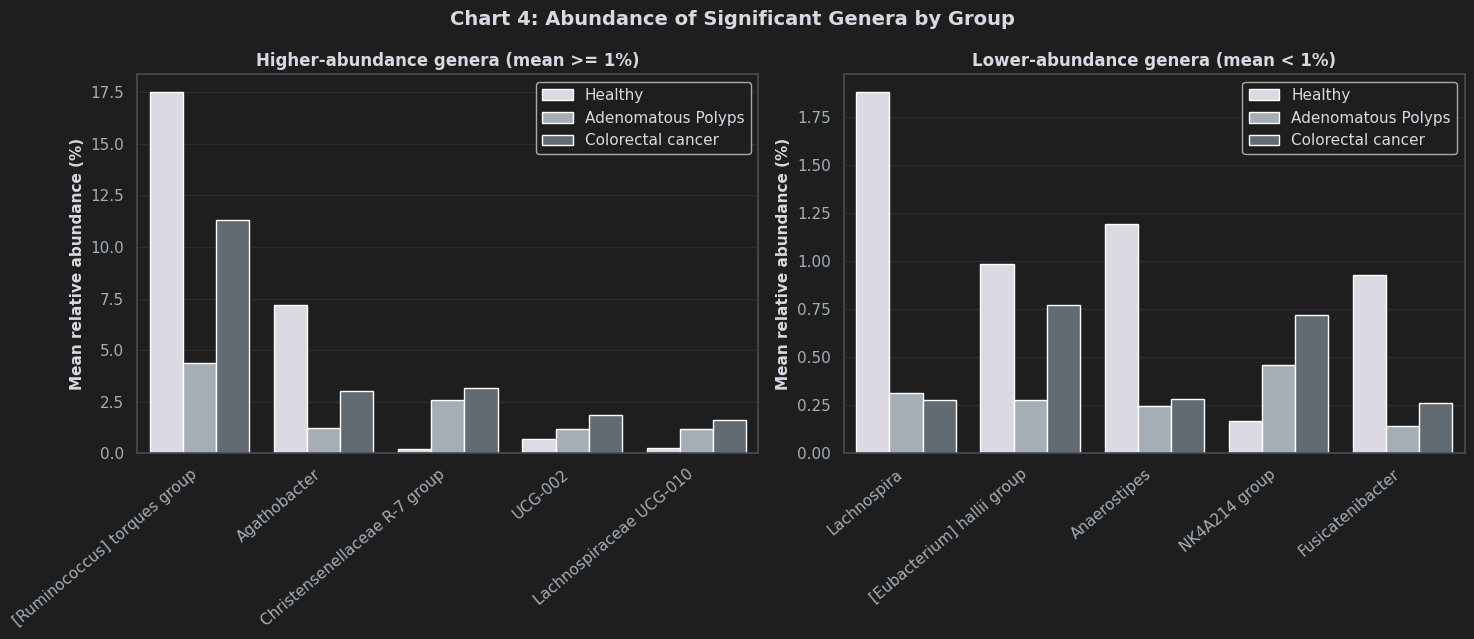

In [ ]:
#Chart 4: Significant genera by group
bar_df = sig.melt(id_vars=["Genus", "Mean_%"], value_vars=[f"Mean_%_{o}" for o in ORDER],
                  var_name="DiseaseStatus", value_name="Abundance")
bar_df["DiseaseStatus"] = bar_df["DiseaseStatus"].str.replace("Mean_%_", "", regex=False)

# Two panels so that high- and low-abundance genera are both readable
panels = [("Higher-abundance genera (mean >= 1%)", bar_df[bar_df["Mean_%"] >= 1]),
          ("Lower-abundance genera (mean < 1%)", bar_df[bar_df["Mean_%"] < 1])]
n_left = max(bar_df.loc[bar_df["Mean_%"] >= 1, "Genus"].nunique(), 1)
n_right = max(bar_df.loc[bar_df["Mean_%"] < 1, "Genus"].nunique(), 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [n_left, n_right]})
for ax, (title, sub) in zip(axes, panels):
    if sub.empty:
        ax.axis("off")
        continue
    order_g = sub.groupby("Genus")["Mean_%"].first().sort_values(ascending=False).index
    sns.barplot(data=sub, x="Genus", y="Abundance", hue="DiseaseStatus", hue_order=ORDER,
                order=order_g, palette=PALETTE, errorbar=None, ax=ax)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Mean relative abundance (%)", fontsize=11, fontweight="bold")
    ax.tick_params(axis="x", rotation=40)
    for lbl in ax.get_xticklabels():
        lbl.set_ha("right")
    ax.get_legend().set_title("")
fig.suptitle("Chart 4: Abundance of Significant Genera by Group", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 14. PCA and KMeans clustering

In [ ]:
#PCA and KMeans clustering
# Scale the tested genera so that abundant genera do not dominate the result
X = StandardScaler().fit_transform(gen[keep])

# PCA: compress the genus table into 5 summary components
pca = PCA(n_components=5, random_state=42)
scores = pca.fit_transform(X)
print("Variance explained by each component (%):", (pca.explained_variance_ratio_ * 100).round(1))
print(f"Total explained by 5 components: {pca.explained_variance_ratio_.sum() * 100:.1f}%")

# KMeans: look for 3 natural clusters without telling the algorithm the disease labels
km = KMeans(n_clusters=3, n_init=10, random_state=42)
clusters = km.fit_predict(scores)

ct = pd.crosstab(meta["DiseaseStatus"].values, clusters, rownames=["Disease status"], colnames=["KMeans cluster"]).loc[ORDER]
display(ct)
ari = adjusted_rand_score(meta["DiseaseStatus"].values, clusters)
print(f"Adjusted Rand Index: {ari:.3f}  (0 = no better than chance, 1 = perfect match with disease groups)")

Variance explained by each component (%): [14.9 11.6  9.4  7.6  6.2]
Total explained by 5 components: 49.8%


KMeans cluster,0,1,2
Disease status,,,
Healthy,8,1,10
Adenomatous Polyps,11,3,5
Colorectal cancer,5,6,10


Adjusted Rand Index: 0.028  (0 = no better than chance, 1 = perfect match with disease groups)


## 15. Export results

In [ ]:
#Export results
analysis_df.to_csv("microbiome_powerbi_ready.csv", index=False, sep=";")

# PCoA coordinates (for a scatter chart in Power BI)
pd.DataFrame(coords[:, :2], index=meta.index, columns=["PCoA1", "PCoA2"]).join(meta["DiseaseStatus"]).to_csv("pcoa_coords.csv")

# Long-format genus abundance table (one row per sample and genus)
genus_long = (gen.reset_index()
                 .melt(id_vars="host_disease", var_name="Genus", value_name="Relative_Abundance")
                 .merge(meta[["DiseaseStatus", "Age", "Sex"]].reset_index(), on="host_disease"))
genus_long.to_csv("microbiome_genus_abundance_long.csv", index=False, sep=";")

# Differential genera results
da.to_csv("differential_genera_results.csv", index=False, sep=";")

print("Export complete")

Export complete
